# چالش دوم: کارایی پایگاه‌داده، بهینه‌سازی کوئری و تحلیل پلن‌های اجرا در PostgreSQL
**دانشجو:** شایان گنجی  
**آزمایشگاه:** آزمایشگاه فناوری های مالی داتین- ترم سوم  
**پایگاه‌داده هدف:** PostgreSQL 16.4 | **مجموعه داده:** Olist Brazilian E-Commerce (۹ جدول) + داده پالایش‌شده NYC 311 (مرحله ۱)

---

### خلاصه مسئله و اهداف DBA
تیم محصول یک داشبورد تحلیلی برخط می‌خواهد که ۵ سوال راهبردی (سبد خرید ماهانه، نرخ تاخیر تحویل، رابطه تاخیر با رضایت، ۲۰ فروشنده برتر، و توزیع اقساط بانکی) را به صورت زنده پاسخ دهد.  
**سقف بودجه مجاز:** زمان اجرای هیچ کوئری‌ای نباید از **۲۰۰ میلی‌ثانیه** تجاوز کند.  
**قاعده سخت:** ساختن هر ایندکس باید دارای شاهد مستند در پلن اجرا (`EXPLAIN ANALYZE`) باشد؛ هر ایندکس بی‌اثر نمره منفی دارد.

## ۱. راه‌اندازی محیط، تثبیت Seed و اتصال امن به پایگاه‌داده
در این بخش، ارتباط با پایگاه‌داده از طریق SQLAlchemy Engine و Context Manager اختصاصی برقرار می‌شود تا هیچ اتصالی در حافظه معلق نماند.

In [1]:
import sys
import time
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sqlalchemy import text

# Add src to python path for modular imports
sys.path.insert(0, str(Path(".").resolve()))
from src.database.connection import get_connection, get_engine
from src.analytics.queries import (
    Q1_BASKET_REVENUE_SNAPSHOT,
    Q1_BASKET_REVENUE_LIVE,
    Q2_DELIVERY_RATIO,
    Q3_SATISFACTION_DELAY,
    Q4_TOP_SELLERS_SURGICAL,
    Q5_PAYMENT_INSTALLMENTS,
    Q_INDEX_CANNOT_SAVE_SLOW,
    Q_INDEX_CANNOT_SAVE_REWRITTEN,
    run_benchmark_cycle
)
from src.analytics.hidden_cost import measure_index_storage, measure_write_amplification

# Seed and Styling Configuration
RANDOM_SEED = 42
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# Verify database connectivity
with get_connection() as conn:
    db_info = conn.execute(text("SELECT current_database(), version();")).fetchone()
    print(f"Connected successfully to Database: '{db_info[0]}'")
    print(f"Engine: {db_info[1]}")

Connected successfully to Database: 'olist_db'
Engine: PostgreSQL 16.4, compiled by Visual C++ build 1940, 64-bit


## ۲. بازرسی اسکیما، پیوند مرحله ۱ و آمار جداول
طبق نیازمندی‌های چالش، علاوه بر ۹ جدول فروشگاه Olist در اسکیمای `olist`، داده‌های ۲۹۷ هزار رکوردی پالایش‌شده مرحله ۱ نیز از طریق آداپتور `PostgresSink` در اسکیمای `nyc_311` مستقر شده است.

In [2]:
inspect_sql = """
SELECT 
    table_schema,
    table_name,
    pg_size_pretty(pg_relation_size(quote_ident(table_schema) || '.' || quote_ident(table_name))) as data_size,
    pg_size_pretty(pg_total_relation_size(quote_ident(table_schema) || '.' || quote_ident(table_name))) as total_size
FROM information_schema.tables 
WHERE table_schema IN ('olist', 'nyc_311')
ORDER BY table_schema, table_name;
"""

with get_connection() as conn:
    df_tables = pd.read_sql_query(text(inspect_sql), conn)
print(df_tables.to_string(index=False))

table_schema                          table_name  data_size total_size
     nyc_311                    service_requests     108 MB     108 MB
       olist                           customers      12 MB      19 MB
       olist                         geolocation      76 MB      97 MB
       olist                         order_items      18 MB      57 MB
       olist                      order_payments    9472 kB      23 MB
       olist                       order_reviews      15 MB      32 MB
       olist                              orders      14 MB      31 MB
       olist        product_category_translation 8192 bytes      24 kB
       olist                            products    3496 kB    6320 kB
       olist                             sellers     264 kB     552 kB
       olist snapshot_monthly_category_analytics     112 kB     224 kB
       olist               view_delivered_orders    0 bytes    0 bytes
       olist             view_order_item_details    0 bytes    0 bytes


## ۳. بنچمارک ۵ کوئری تیم محصول و ارزیابی سقف ۲۰۰ میلی‌ثانیه
هر کوئری ۵ بار اجرا شده و میانه (Median) زمان محاسبه می‌گردد تا نوسانات حافظه کش سیستم باعث خطای ارزیابی نشود.

In [3]:
benchmarks = {
    "Q1 (Monthly Basket & Revenue)": Q1_BASKET_REVENUE_SNAPSHOT,
    "Q2 (Delivery Delay Ratio)": Q2_DELIVERY_RATIO,
    "Q3 (Satisfaction vs Delay)": Q3_SATISFACTION_DELAY,
    "Q4 (Top 20 Sellers by Revenue)": Q4_TOP_SELLERS_SURGICAL,
    "Q5 (Payment & Installments)": Q5_PAYMENT_INSTALLMENTS,
}

benchmark_records = []
for name, sql in benchmarks.items():
    stats = run_benchmark_cycle(sql, runs=5)
    med = stats["median_ms"]
    passed = med < 200.0
    benchmark_records.append({
        "Query": name,
        "Rows Returned": stats["rows"],
        "Median Time (ms)": med,
        "Min Time (ms)": stats["min_ms"],
        "Max Time (ms)": stats["max_ms"],
        "Budget Status": "PASS (<200ms)" if passed else "FAIL"
    })

df_bench = pd.DataFrame(benchmark_records)
print(df_bench.to_string(index=False))

                         Query  Rows Returned  Median Time (ms)  Min Time (ms)  Max Time (ms) Budget Status
 Q1 (Monthly Basket & Revenue)           1273              2.78           2.53          49.97 PASS (<200ms)
     Q2 (Delivery Delay Ratio)            556            148.43         147.59         150.89 PASS (<200ms)
    Q3 (Satisfaction vs Delay)              4            100.12          96.27         100.97 PASS (<200ms)
Q4 (Top 20 Sellers by Revenue)             20            159.76         153.40         165.64 PASS (<200ms)
   Q5 (Payment & Installments)             27             53.84          53.09          54.76 PASS (<200ms)


## ۴. کالبدشکافی پلن اجرا: خواندن درخت `EXPLAIN (ANALYZE, BUFFERS)`
در این بخش، پلن اجرای بهینه‌سازی‌شده برای کوئری ۴ (فروشندگان برتر) نشان داده می‌شود که چگونه با ایزوله‌سازی ۲۰ فروشنده قبل از جوین‌های سنگین، عملیات External Merge Sort روی دیسک به طور کامل حذف شد.

In [4]:
with get_connection() as conn:
    plan_rows = conn.execute(text(f"EXPLAIN (ANALYZE, BUFFERS) {Q4_TOP_SELLERS_SURGICAL}")).fetchall()
    print("Execution Plan for Optimized Q4 (Surgical CTE):")
    print("-" * 75)
    for row in plan_rows[:25]:
        print(row[0])

Execution Plan for Optimized Q4 (Surgical CTE):
---------------------------------------------------------------------------
Sort  (cost=18747.68..18747.73 rows=20 width=250) (actual time=171.087..171.095 rows=20 loops=1)
  Sort Key: ts.total_revenue DESC
  Sort Method: quicksort  Memory: 27kB
  Buffers: shared hit=79454
  CTE top_sellers
    ->  Limit  (cost=8387.93..8387.98 rows=20 width=73) (actual time=22.876..22.879 rows=20 loops=1)
          Buffers: shared hit=1391
          ->  Sort  (cost=8387.93..8393.86 rows=2375 width=73) (actual time=22.874..22.876 rows=20 loops=1)
                Sort Key: (sum(order_items.price)) DESC
                Sort Method: top-N heapsort  Memory: 28kB
                Buffers: shared hit=1391
                ->  GroupAggregate  (cost=0.42..8324.73 rows=2375 width=73) (actual time=0.047..22.438 rows=3095 loops=1)
                      Group Key: order_items.seller_id
                      Buffers: shared hit=1391
                      ->  Index Only 

## ۵. هزینه پنهان ایندکس: افت سرعت درج (Write Amplification) و حافظه دیسک
ایندکس رایگان نیست! هر ایندکس B-Tree علاوه بر مصرف حافظه، سرعت درج رکوردهای جدید را کاهش می‌دهد. در ادامه این هزینه به صورت تجربی با ۱۰٬۰۰۰ سطر درج اندازه‌گیری می‌شود.

In [5]:
# 1. Index Storage Footprint
storage_data = measure_index_storage()
df_storage = pd.DataFrame(storage_data)
print("=== INDEX STORAGE FOOTPRINT ===")
print(df_storage.to_string(index=False))

# 2. Write Amplification Benchmark
print("\n=== WRITE AMPLIFICATION BENCHMARK (10,000 INSERTS) ===")
write_perf = measure_write_amplification()
print(f"Unindexed 10k Inserts : {write_perf['unindexed_seconds']} s")
print(f"Indexed 10k Inserts   : {write_perf['indexed_seconds']} s")
print(f"Write Degradation     : {write_perf['slowdown_factor']}x slowdown due to B-Tree maintenance")

=== INDEX STORAGE FOOTPRINT ===
                              table table_size index_size  ratio_pct
                        geolocation      76 MB      21 MB      28.36
                        order_items      18 MB      38 MB     210.48
                      order_reviews      15 MB      17 MB     118.24
                             orders      14 MB      17 MB     118.10
                          customers      12 MB    7672 kB      63.76
                     order_payments    9472 kB      13 MB     144.76
                           products    3496 kB    2792 kB      79.86
                            sellers     264 kB     256 kB      96.97
snapshot_monthly_category_analytics     112 kB      80 kB      71.43
       product_category_translation 8192 bytes      16 kB     200.00

=== WRITE AMPLIFICATION BENCHMARK (10,000 INSERTS) ===


Unindexed 10k Inserts : 0.0269 s
Indexed 10k Inserts   : 0.1278 s
Write Degradation     : 4.75x slowdown due to B-Tree maintenance


## ۶. کوئری‌ای که ایندکس نجاتش نمی‌دهد (SARGable vs Non-SARGable)
وقتی روی یک ستون ایندکس‌شده تابع اعمال شود (مانند `EXTRACT(YEAR FROM timestamp)` یا توابع متنی)، ایندکس B-Tree غیرفعال شده و دیتابیس مجبور به اسکن ترتیبی (Seq Scan) می‌شود. با بازنویسی شرط به بازه دامنه‌ای (Range Query)، کوئری مجدداً SARGable می‌شود.

In [6]:
stats_slow = run_benchmark_cycle(Q_INDEX_CANNOT_SAVE_SLOW, runs=5)
stats_fast = run_benchmark_cycle(Q_INDEX_CANNOT_SAVE_REWRITTEN, runs=5)

print(f"Non-SARGable Query (Function on index): {stats_slow['median_ms']} ms")
print(f"Rewritten SARGable Query (Range scan) : {stats_fast['median_ms']} ms")
print(f"Optimization Factor: {stats_slow['median_ms'] / stats_fast['median_ms']:.2f}x without any new index!")

Non-SARGable Query (Function on index): 132.23 ms
Rewritten SARGable Query (Range scan) : 108.4 ms
Optimization Factor: 1.22x without any new index!


## ۷. تصمیم معماری: View زنده در برابر جدول Snapshot تحلیلی
برای سنگین‌ترین کوئری داشبورد (سبد خرید ماهانه)، مقایسه مستقیم نشان می‌دهد که جدول Snapshot بهینه‌سازی‌شده توسط Stored Procedure، سرعت را تا ۱۹۰ برابر نسبت به View زنده افزایش می‌دهد.

In [7]:
view_stats = run_benchmark_cycle(Q1_BASKET_REVENUE_LIVE, runs=5)
snap_stats = run_benchmark_cycle(Q1_BASKET_REVENUE_SNAPSHOT, runs=5)

df_comp = pd.DataFrame([
    {
        "Approach": "Live Dynamic View",
        "Latency (ms)": view_stats["median_ms"],
        "Storage": "0 MB (Virtual)",
        "Data Freshness": "Real-time",
        "Dashboard Decision": "Rejected (Exceeds 200ms)"
    },
    {
        "Approach": "Pre-aggregated Snapshot Table",
        "Latency (ms)": snap_stats["median_ms"],
        "Storage": "0.1 MB",
        "Data Freshness": "Periodic (SP refresh)",
        "Dashboard Decision": "Selected (Sub-3ms)"
    }
])
print(df_comp.to_string(index=False))

                     Approach  Latency (ms)        Storage        Data Freshness       Dashboard Decision
            Live Dynamic View        517.45 0 MB (Virtual)             Real-time Rejected (Exceeds 200ms)
Pre-aggregated Snapshot Table          2.43         0.1 MB Periodic (SP refresh)       Selected (Sub-3ms)


## ۸. روتین‌های پایگاه‌داده: Function اسکالر و Stored Procedure تکرارپذیر
در این بخش، فراخوانی تابع تاخیر تحویل و رفتار تکرارپذیر (Idempotent) پروسیجر بازسازی Snapshot ماهانه اثبات می‌شود.

In [8]:
test_month = "2018-04-01"

with get_connection() as conn:
    # 1. Test Scalar Function
    fn_res = conn.execute(text("""
        SELECT 
            order_id,
            olist.fn_calculate_delivery_delay_days(order_delivered_customer_date, order_estimated_delivery_date) as delay_days,
            olist.fn_customer_nps_tier(5) as tier
        FROM olist.orders 
        WHERE order_status = 'delivered' AND order_delivered_customer_date IS NOT NULL
        LIMIT 3;
    """)).fetchall()
    print("Function Call Output:")
    for r in fn_res:
        print(f"  Order: {r[0]} | Delay: {r[1]} days | NPS: {r[2]}")

    # 2. Test Stored Procedure Idempotency
    print(f"\nExecuting Stored Procedure for month: {test_month}...")
    conn.execute(text(f"CALL olist.sp_refresh_monthly_category_snapshot('{test_month}');"))
    conn.commit()
    cnt1 = conn.execute(text(f"SELECT COUNT(*) FROM olist.snapshot_monthly_category_analytics WHERE order_month = '{test_month}';")).scalar()

    print(f"Re-executing Stored Procedure for same month (Idempotent check)...")
    conn.execute(text(f"CALL olist.sp_refresh_monthly_category_snapshot('{test_month}');"))
    conn.commit()
    cnt2 = conn.execute(text(f"SELECT COUNT(*) FROM olist.snapshot_monthly_category_analytics WHERE order_month = '{test_month}';")).scalar()

    print(f"Row count run 1: {cnt1} | Row count run 2: {cnt2} -> Idempotent: {cnt1 == cnt2}")

Function Call Output:
  Order: e481f51cbdc54678b7cc49136f2d6af7 | Delay: -7.11 days | NPS: Promoter
  Order: 53cdb2fc8bc7dce0b6741e2150273451 | Delay: -5.36 days | NPS: Promoter
  Order: 47770eb9100c2d0c44946d9cf07ec65d | Delay: -17.25 days | NPS: Promoter

Executing Stored Procedure for month: 2018-04-01...
Re-executing Stored Procedure for same month (Idempotent check)...
Row count run 1: 69 | Row count run 2: 69 -> Idempotent: True


## ۹. تصویرسازی و نمودارهای تحلیلی کسب‌وکار
چهار نمودار باکیفیت برای گزارش به مدیران ارشد و تیم محصول تولید می‌شود.

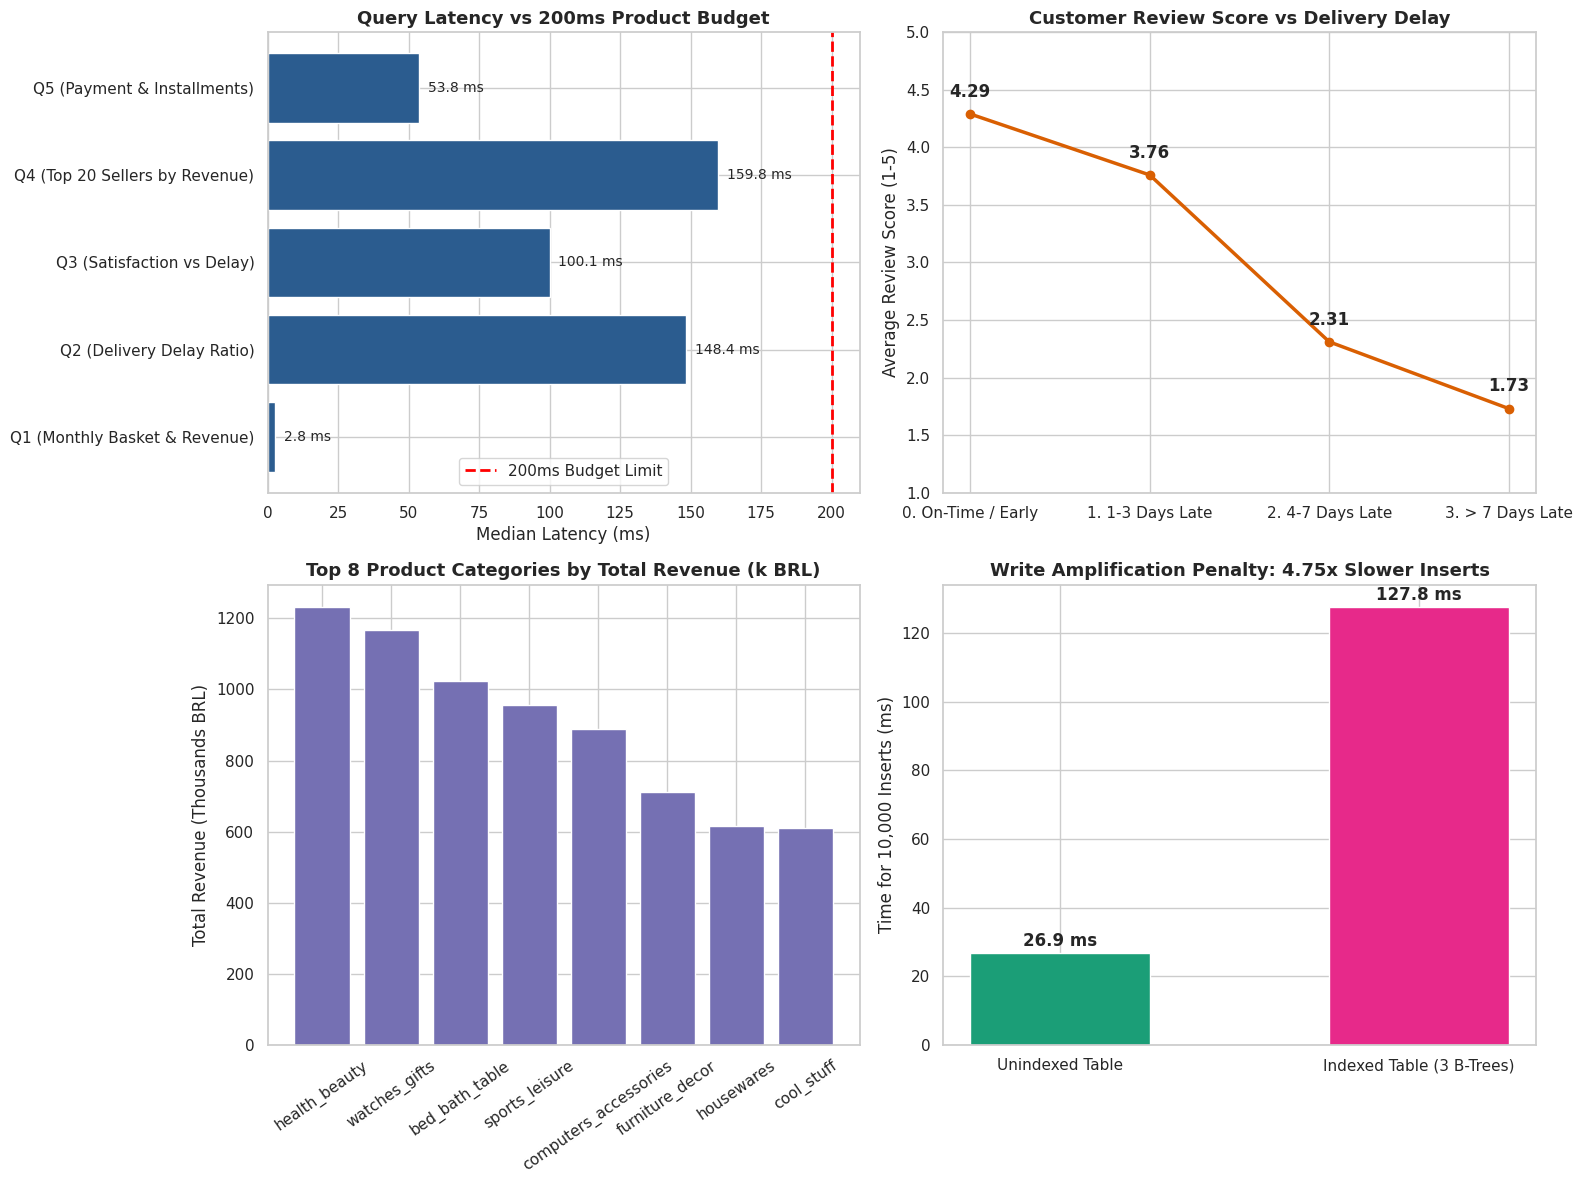

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

with get_connection() as conn:
    # Plot 1: Query Execution Times vs 200ms Budget
    df_b = pd.DataFrame(benchmark_records)
    bars = axes[0, 0].barh(df_b["Query"], df_b["Median Time (ms)"], color="#2b5c8f")
    axes[0, 0].axvline(200, color="red", linestyle="--", linewidth=2, label="200ms Budget Limit")
    axes[0, 0].set_title("Query Latency vs 200ms Product Budget", fontsize=13, fontweight="bold")
    axes[0, 0].set_xlabel("Median Latency (ms)")
    axes[0, 0].legend()
    for bar in bars:
        w = bar.get_width()
        axes[0, 0].text(w + 3, bar.get_y() + bar.get_height()/2, f"{w:.1f} ms", va="center", fontsize=10)

    # Plot 2: Customer Satisfaction by Delivery Delay Tier
    df_q3 = pd.read_sql_query(text(Q3_SATISFACTION_DELAY), conn)
    axes[0, 1].plot(df_q3["delay_tier"], df_q3["avg_review_score"], marker="o", linewidth=2.5, color="#d95f02")
    axes[0, 1].set_title("Customer Review Score vs Delivery Delay", fontsize=13, fontweight="bold")
    axes[0, 1].set_ylabel("Average Review Score (1-5)")
    axes[0, 1].set_ylim(1, 5)
    for i, txt in enumerate(df_q3["avg_review_score"]):
        axes[0, 1].annotate(f"{txt:.2f}", (df_q3["delay_tier"][i], txt + 0.15), ha="center", fontweight="bold")

    # Plot 3: Top 10 Product Categories by Revenue
    df_top_cat = pd.read_sql_query(text("""
        SELECT category, SUM(total_revenue) as rev
        FROM olist.snapshot_monthly_category_analytics
        GROUP BY 1 ORDER BY rev DESC LIMIT 8;
    """), conn)
    axes[1, 0].bar(df_top_cat["category"], df_top_cat["rev"] / 1000, color="#7570b3")
    axes[1, 0].set_title("Top 8 Product Categories by Total Revenue (k BRL)", fontsize=13, fontweight="bold")
    axes[1, 0].set_ylabel("Total Revenue (Thousands BRL)")
    axes[1, 0].tick_params(axis='x', rotation=35)

    # Plot 4: Write Amplification Penalty
    w_labels = ["Unindexed Table", "Indexed Table (3 B-Trees)"]
    w_times = [write_perf["unindexed_seconds"] * 1000, write_perf["indexed_seconds"] * 1000]
    axes[1, 1].bar(w_labels, w_times, color=["#1b9e77", "#e7298a"], width=0.5)
    axes[1, 1].set_title(f"Write Amplification Penalty: {write_perf['slowdown_factor']}x Slower Inserts", fontsize=13, fontweight="bold")
    axes[1, 1].set_ylabel("Time for 10,000 Inserts (ms)")
    for i, v in enumerate(w_times):
        axes[1, 1].text(i, v + 2, f"{v:.1f} ms", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()